In [7]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent / "src"))

from logistic_regression import LogisticRegression, sigmoid

from optimizers import (
    GradientDescent,
    Momentum,
    Adam
)

import numpy as np
import matplotlib.pyplot as plt

In [8]:
np.random.seed(42)

X = np.random.randn(500, 3)

true_weights = np.array([1.5, -2.0, 0.8])

probabilities = sigmoid(X @ true_weights)

y = (
    np.random.rand(500) < probabilities
).astype(int)

print("Dataset shape:", X.shape)
print("Target shape:", y.shape)

Dataset shape: (500, 3)
Target shape: (500,)


In [9]:
experiments = {
    "Batch GD": {
        "optimizer": GradientDescent(learning_rate=0.1),
        "batch_size": 500
    },

    "SGD": {
        "optimizer": GradientDescent(learning_rate=0.01),
        "batch_size": 1
    },

    "Momentum": {
        "optimizer": Momentum(
            learning_rate=0.1,
            beta=0.9
        ),
        "batch_size": 500
    },

    "Adam": {
        "optimizer": Adam(learning_rate=0.01),
        "batch_size": 500
    }
}

results = {}

for name, config in experiments.items():

    model = LogisticRegression(l2=0.01)

    model.fit(
        X,
        y,
        optimizer=config["optimizer"],
        epochs=100,
        batch_size=config["batch_size"]
    )

    results[name] = model

    print(
        f"{name:12s} | "
        f"Final Loss: {model.loss_history[-1]:.6f}"
    )

Batch GD     | Final Loss: 0.426904
SGD          | Final Loss: 0.403444
Momentum     | Final Loss: 0.424217
Adam         | Final Loss: 0.451321


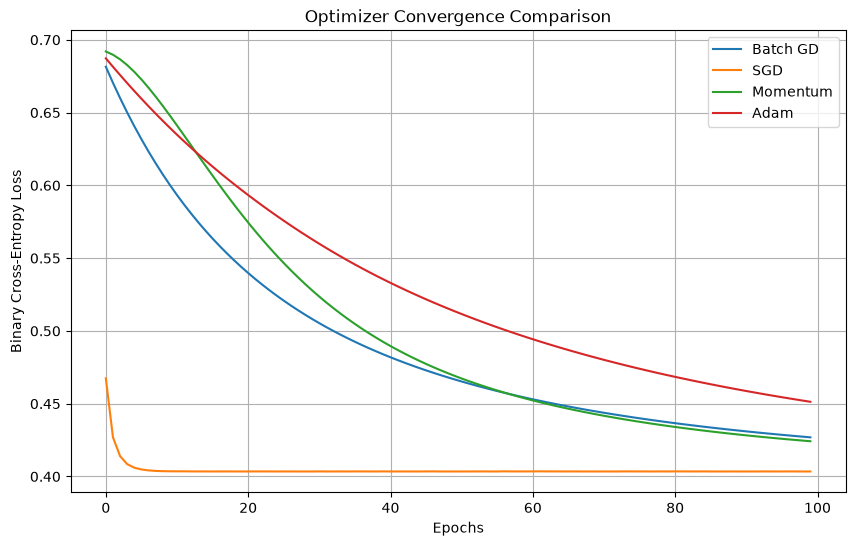

In [10]:
plt.figure(figsize=(10, 6))

for name, model in results.items():
    plt.plot(
        model.loss_history,
        label=name
    )

plt.xlabel("Epochs")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Optimizer Convergence Comparison")

plt.legend()
plt.grid(True)

plt.show()